# Timeseries — Peramalan Zero-shot dengan Chronos (model fondasi, tanpa melatih)
**Kapan dipakai:** butuh ramalan bagus dengan cepat, atau data terlalu pendek untuk melatih
model. Chronos sudah dilatih di jutaan deret waktu: cukup beri riwayat, keluar ramalan +
interval.
- **Chronos-2** (utama): satu atau banyak deret sekaligus, interval kuantil.
- **Chronos-Bolt small** (alternatif, baris `#`): lebih kecil dan cepat.

**Data demo:** bagian 1 satu deret (CO2 bulanan), bagian 2 442 deret harga pangan SINTETIS
(pola soal Datavidia). Bobot lokal (offline). GPU disarankan.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from chronos import BaseChronosPipeline, Chronos2Pipeline
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

## Konfigurasi

In [2]:
SINGLE_CSV = "../../../data_latihan/timeseries/forecasting/co2_monthly.csv"
DATA_FOLDER = "../../../data_latihan/timeseries/global"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/harga_pangan_SINTETIS_train.csv"
TEST_CSV = f"{DATA_FOLDER}/harga_pangan_SINTETIS_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/harga_pangan_SINTETIS_test_labels.csv"   # hanya di data latihan
CHRONOS_2 = "../../../pretrained/chronos_2"
CHRONOS_BOLT = "../../../pretrained/chronos_bolt_small"

DATE_COL = "date"
VALUE_COL = "value"              # bagian 1
TARGET = "harga"                 # bagian 2
SERIES_COLS = ["provinsi", "komoditas"]   # bagian 2: kolom yang menandai satu deret
HORIZON = 36                     # bagian 1: jumlah bulan yang diramal (= panjang data uji)
SEASON_LENGTH = 12               # untuk pembanding seasonal naive
QUANTILES = [0.1, 0.5, 0.9]      # interval 80%: kuantil 0.1 sampai 0.9
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Bagian 1 — satu deret
Chronos-2 meminta tabel panjang: kolom `id` (nama deret), `timestamp`, `target`.

In [3]:
series = pd.read_csv(SINGLE_CSV, parse_dates=[DATE_COL])
history = series.iloc[:-HORIZON]
actual = series.iloc[-HORIZON:]
print(series.shape, "| riwayat:", len(history), "| uji:", len(actual))

context = pd.DataFrame()
context["id"] = ["deret_1"] * len(history)
context["timestamp"] = history[DATE_COL].to_numpy()
context["target"] = history[VALUE_COL].to_numpy()

model = Chronos2Pipeline.from_pretrained(CHRONOS_2, device_map=DEVICE)
forecast = model.predict_df(context, prediction_length=HORIZON, quantile_levels=QUANTILES,
                            id_column="id", timestamp_column="timestamp", target="target")
forecast.head()

(526, 2) | riwayat: 490 | uji: 36


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,id,timestamp,target_name,predictions,0.1,0.5,0.9
0,deret_1,1999-01-01,target,368.024475,367.147278,368.024475,368.842285
1,deret_1,1999-02-01,target,368.813080,367.874695,368.813080,369.696411
2,deret_1,1999-03-01,target,369.770813,368.733246,369.770813,370.640320
3,deret_1,1999-04-01,target,370.678650,369.901367,370.678650,372.005402
4,deret_1,1999-05-01,target,371.247131,370.176331,371.247131,372.328033


## Bandingkan dengan seasonal naive (ulang musim terakhir)

MAE seasonal naive: 2.866
MAE Chronos-2     : 0.866


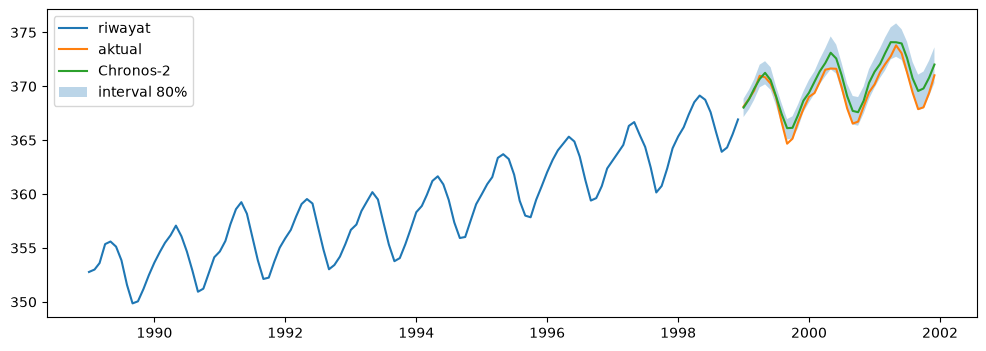

In [4]:
naive = np.resize(history[VALUE_COL].to_numpy()[-SEASON_LENGTH:], HORIZON)
print("MAE seasonal naive:", round(mean_absolute_error(actual[VALUE_COL], naive), 3))
print("MAE Chronos-2     :", round(mean_absolute_error(actual[VALUE_COL],
                                                       forecast["predictions"]), 3))

# Alternatif: Chronos-Bolt small (input tensor, keluaran kuantil [deret, langkah, kuantil])
# bolt = BaseChronosPipeline.from_pretrained(CHRONOS_BOLT, device_map=DEVICE)
# past_values = torch.tensor(history[VALUE_COL].to_numpy())
# bolt_quantiles, bolt_mean = bolt.predict_quantiles(past_values, prediction_length=HORIZON,
#                                                    quantile_levels=QUANTILES)
# bolt_median = bolt_quantiles[0, :, 1].numpy()
# print("MAE Chronos-Bolt  :", round(mean_absolute_error(actual[VALUE_COL], bolt_median), 3))

plt.figure(figsize=(12, 4))
plt.plot(history[DATE_COL].iloc[-120:], history[VALUE_COL].iloc[-120:], label="riwayat")
plt.plot(actual[DATE_COL], actual[VALUE_COL], label="aktual")
plt.plot(actual[DATE_COL], forecast["predictions"], label="Chronos-2")
plt.fill_between(actual[DATE_COL], forecast["0.1"], forecast["0.9"], alpha=0.3,
                 label="interval 80%")
plt.legend()
plt.savefig("ramalan_satu_deret.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 2 — banyak deret sekaligus (harga 13 komoditas x 34 provinsi)
Satu deret = satu pasangan provinsi + komoditas. Harga kosong diisi nilai sebelumnya (ffill)
lalu sesudahnya (bfill) per deret, supaya Chronos menerima riwayat tanpa lubang.

In [5]:
train = pd.read_csv(TRAIN_CSV, parse_dates=[DATE_COL])
test = pd.read_csv(TEST_CSV, parse_dates=[DATE_COL])
train["series_id"] = train[SERIES_COLS[0]] + "|" + train[SERIES_COLS[1]]
test["series_id"] = test[SERIES_COLS[0]] + "|" + test[SERIES_COLS[1]]
train = train.sort_values(["series_id", DATE_COL])
train[TARGET] = train.groupby("series_id")[TARGET].ffill()
train[TARGET] = train.groupby("series_id")[TARGET].bfill()
test_horizon = test[DATE_COL].nunique()
print("deret:", train["series_id"].nunique(), "| horizon:", test_horizon, "hari")

many_forecast = model.predict_df(train, prediction_length=test_horizon,
                                 quantile_levels=QUANTILES, id_column="series_id",
                                 timestamp_column=DATE_COL, target=TARGET)
print(many_forecast.shape)

deret: 442 | horizon: 92 hari


(40664, 7)


## Tempel ramalan ke baris test (kunci = series_id + tanggal, lewat dict)

In [6]:
forecast_keys = many_forecast["series_id"] + "|" + many_forecast[DATE_COL].astype(str)
forecast_by_key = dict(zip(forecast_keys, many_forecast["predictions"]))
test_keys = test["series_id"] + "|" + test[DATE_COL].astype(str)
predictions = test_keys.map(forecast_by_key)
print("baris test tanpa ramalan:", predictions.isna().sum())

baris test tanpa ramalan: 0


## Submission

In [7]:
submission = pd.DataFrame()
submission["id"] = test["id"]
submission["harga"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,harga
0,0,13651.317383
1,1,13654.292969
2,2,13659.060547
3,3,13659.518555
4,4,13656.676758


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Kunci juga punya harga kosong: dinilai yang ada saja.

In [8]:
test_key = pd.read_csv(TEST_KEY_CSV)[TARGET]
has_price = test_key.notna()
mape = mean_absolute_percentage_error(test_key[has_price], predictions[has_price]) * 100
print("MAPE Chronos-2 zero-shot:", round(mape, 3), "%")

MAPE Chronos-2 zero-shot: 3.028 %
